# ICS Anomaly Detection Benchmark

One notebook, start to finish: load the real SWaT data, see exactly what `StandardScaler` does to all 51 sensors, look at the cleaned data the models actually train on, run every registered detector, and compare them with loss curves and score plots -- all through clean imports from `src/`, nothing re-implemented here.


## Setup

The two environment variables below must be set **before** XGBoost or PyTorch
are imported anywhere in this process. Both libraries bundle their own copy of
the OpenMP runtime (`libomp.dylib`), and on macOS, loading both into one
process without this can deadlock silently — the kernel just hangs with 0%
CPU, no error, no traceback. This was hit and diagnosed during CLI runs of
this same pipeline.


In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import sys
from pathlib import Path

# This notebook lives in notebooks/; the project modules live in ../src.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = ROOT / "src"
assert SRC.exists(), f"expected {SRC} to exist — run this notebook from notebooks/"
sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

get_ipython().run_line_magic("matplotlib", "inline")
sns.set_theme(style="whitegrid")

print(f"project root: {ROOT}")


project root: /Users/santhosh/Desktop/urex-ics


## Choose a dataset

`DATASET` must be a key in `data.LOADERS` (== `config.DATASET_INFO`). Change
this one line and re-run the notebook to benchmark a different dataset — no
other cell needs editing.

Not every registered dataset has a working loader yet — `src/data.py` ships
`load_wadi`, `load_morris`, and `load_batadal` as stubs that raise
`NotImplementedError` until each dataset's files arrive and its loader is
filled in (see `notes/datasets.md` for status). `load_swat` is currently the
only one implemented — this project's scope is SWaT only for now.


In [2]:
from data import LOADERS

DATASET = "swat"  # <-- change this, then Run All

print(f"registered: {list(LOADERS)}")
print(f"running:    {DATASET!r}")

registered: ['swat', 'wadi', 'morris', 'batadal']
running:    'swat'


## Load the dataset

`data.load(name)` dispatches to that dataset's loader (`load_swat()`: reads
the two raw iTrust xlsx files, builds the `label` column, handles SWaT's
specific cleanup) and then applies `chronological_split()` — 60% train / 20%
val / 20% test targets, in time order, nudged to never bisect an attack
episode, scaler fit on train only. The split logic and its guardrails are
shared by every dataset in `src/data.py`; only the loader itself is
dataset-specific.


In [3]:
from config import RESULTS, THRESHOLD_PERCENTILE, DATASET_INFO
from data import load

info = DATASET_INFO.get(DATASET, {})
print(f"{DATASET}: {info}")
print()

split = load(DATASET)
print(split.summary())


swat: {'source': 'iTrust, SUTD', 'domain': 'water treatment', 'temporal_dependency': 'high', 'role': 'primary, literature comparability'}



/Users/santhosh/.venv/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


/Users/santhosh/.venv/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


swat: 51 features
  train  555,071 rows  anomaly rate 0.0093
  val    185,024 rows  anomaly rate 0.2295
  test   185,024 rows  anomaly rate 0.0376


In [4]:
print(f"features: {split.n_features}")
print(f"first 10 feature names: {split.feature_names[:10]}")


features: 51
first 10 feature names: ['FIT101', 'LIT101', 'MV101', 'P101', 'P102', 'AIT201', 'AIT202', 'AIT203', 'FIT201', 'MV201']


## Raw data, before anything is touched

`load_swat()` on its own (without the split) returns the full, time-sorted DataFrame straight out of the two iTrust xlsx files: 51 sensor/actuator columns plus `label`, nothing scaled, nothing split yet. This is what's actually sitting in the raw Excel files.


In [5]:
from data import load_swat

df_raw = load_swat()
print(f"{len(df_raw):,} rows, {df_raw.shape[1] - 1} sensor columns + label")
df_raw.head()


/Users/santhosh/.venv/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


/Users/santhosh/.venv/lib/python3.14/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


925,119 rows, 51 sensor columns + label


,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,MV201,...,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,label
0,2.630433,501.7288,2,2,1,261.3753,8.336837,447.5775,2.459616,2,...,2,1,254.0855,1.041233,193.1396,0.000064,1,1,1,0
1,2.617622,501.6895,2,2,1,261.3753,8.336837,447.4750,2.460001,2,...,2,1,254.0695,1.041233,193.1396,0.000064,1,1,1,0
2,2.608974,501.4540,2,2,1,261.3753,8.338439,447.2699,2.460385,2,...,2,1,253.9573,1.041233,192.9794,0.000064,1,1,1,0
3,2.598405,501.8858,2,2,1,261.3753,8.339080,447.2699,2.462179,2,...,2,1,253.9253,1.041233,192.9794,0.000064,1,1,1,0
4,2.575986,501.8858,2,2,1,261.3753,8.339080,447.2699,2.462179,2,...,2,1,253.9253,1.041233,192.9794,0.000064,1,1,1,0


## StandardScaler: what scaling actually did to all 51 sensors

SWaT's 51 sensors live on wildly different scales — flow rates near 0, tank levels in the hundreds, a handful of binary actuator states. `chronological_split()` fits one `StandardScaler` on the **training rows only** and applies it unchanged to val/test (fitting on the full series would leak test-set statistics into training).

`scaling_summary()` below lines up each sensor's raw mean/std/min/max against its scaled mean/std, so the effect is checkable directly rather than assumed.


In [6]:
from visualize import scaling_summary, plot_scaling_effect

summary = scaling_summary(df_raw, split)
print(f"all {len(summary)} sensors; first 10 shown:")
summary.head(10)


all 51 sensors; first 10 shown:


,sensor,raw_mean,raw_std,raw_min,raw_max,scaled_mean,scaled_std
0,FIT101,1.840881,1.137238,0.0000,2.745092,1.884298e-17,1.0
1,LIT101,593.765283,114.425255,486.3809,925.032300,1.286238e-16,1.0
2,MV101,1.716480,0.459926,0.0000,2.000000,4.342077e-17,1.0
3,P101,1.746503,0.435013,1.0000,2.000000,2.490550e-16,1.0
4,P102,1.000802,0.028303,1.0000,2.000000,-5.570967e-16,1.0
5,AIT201,263.274294,4.759323,252.8518,272.526300,-7.078405e-15,1.0
6,AIT202,8.385754,0.088963,6.0000,8.988273,-5.570967e-15,1.0
7,AIT203,341.547952,40.902124,312.2789,567.469900,-1.572979e-16,1.0
8,FIT201,1.826995,1.062517,0.0000,2.804857,1.753216e-16,1.0
9,MV201,1.743209,0.445362,0.0000,2.000000,-8.028746e-17,1.0


saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-scaling-effect.png


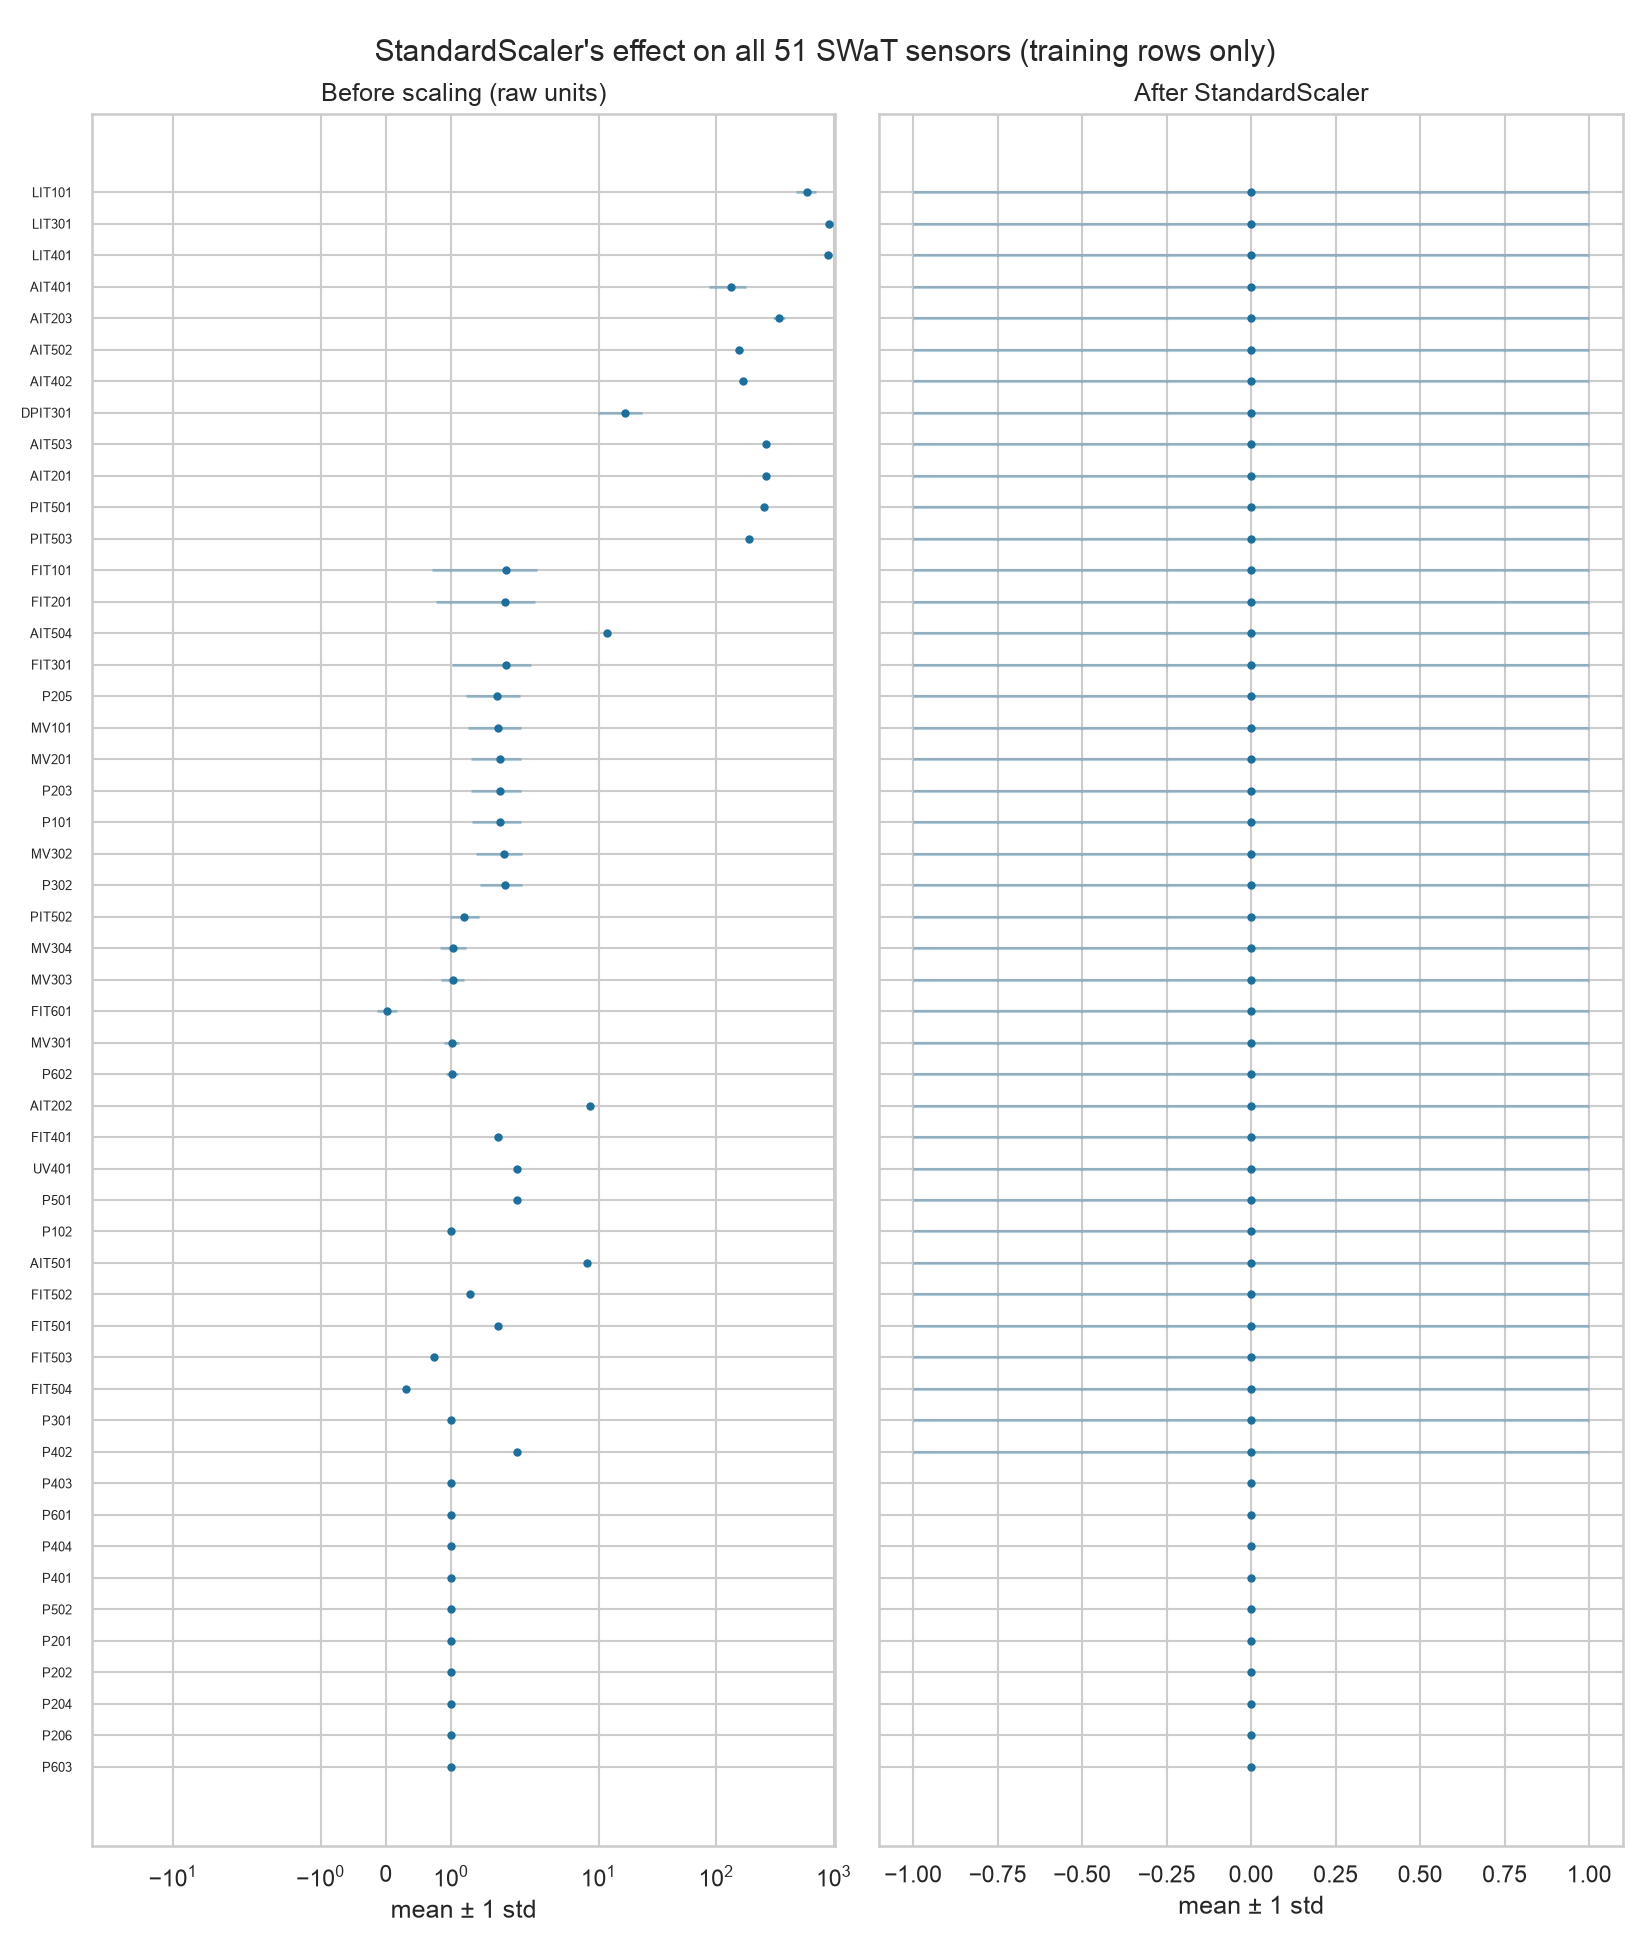

In [7]:
fig_dir = RESULTS / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

scaling_png = fig_dir / f"{DATASET}-scaling-effect.png"
plot_scaling_effect(summary, scaling_png)
display(Image(filename=str(scaling_png)))


## The cleaned data every model actually trains on

`split.X_train` is a plain numpy array (scaled, no column names) — this is that same array shown as a real DataFrame, labelled with `split.feature_names`, so it's checkable row-by-row against the raw preview above. Same rows, after `load_swat()`'s cleanup and the scaler, nothing else changed.


In [8]:
cleaned = pd.DataFrame(split.X_train[:8], columns=split.feature_names)
cleaned.insert(0, "label", split.y_train[:8])
cleaned.round(3)


,label,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,...,FIT504,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603
0,0,0.694,-0.804,0.616,0.583,-0.028,-0.399,-0.550,2.592,0.595,...,0.076,0.032,0.0,0.528,-0.699,0.650,-0.098,0.0,-0.091,0.0
1,0,0.683,-0.805,0.616,0.583,-0.028,-0.399,-0.550,2.590,0.596,...,0.076,0.032,0.0,0.524,-0.699,0.650,-0.098,0.0,-0.091,0.0
2,0,0.675,-0.807,0.616,0.583,-0.028,-0.399,-0.532,2.585,0.596,...,0.076,0.032,0.0,0.498,-0.699,0.605,-0.098,0.0,-0.091,0.0
3,0,0.666,-0.803,0.616,0.583,-0.028,-0.399,-0.525,2.585,0.598,...,0.076,0.032,0.0,0.491,-0.699,0.605,-0.098,0.0,-0.091,0.0
4,0,0.646,-0.803,0.616,0.583,-0.028,-0.399,-0.525,2.585,0.598,...,0.076,0.032,0.0,0.491,-0.699,0.605,-0.098,0.0,-0.091,0.0
5,0,0.633,-0.803,0.616,0.583,-0.028,-0.399,-0.525,2.582,0.597,...,0.076,0.032,0.0,0.491,-0.699,0.605,-0.098,0.0,-0.091,0.0
6,0,0.618,-0.802,0.616,0.583,-0.028,-0.399,-0.525,2.582,0.595,...,0.076,0.032,0.0,0.491,-0.699,0.605,-0.098,0.0,-0.091,0.0
7,0,0.604,-0.803,0.616,0.583,-0.028,-0.399,-0.525,2.580,0.595,...,0.076,0.032,0.0,0.468,-0.699,0.583,-0.098,0.0,-0.091,0.0


## Where train / val / test fall in time

The split is chronological and episode-aware — the two cutoffs don't land at clean 60/20/20 marks because the later one is nudged forward to avoid slicing a real attack episode in half (see `_episode_safe_cut` in `src/data.py`). This plots one real sensor's raw value across the whole timeline, coloured by which split each second landed in.


saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-split-timeline.png


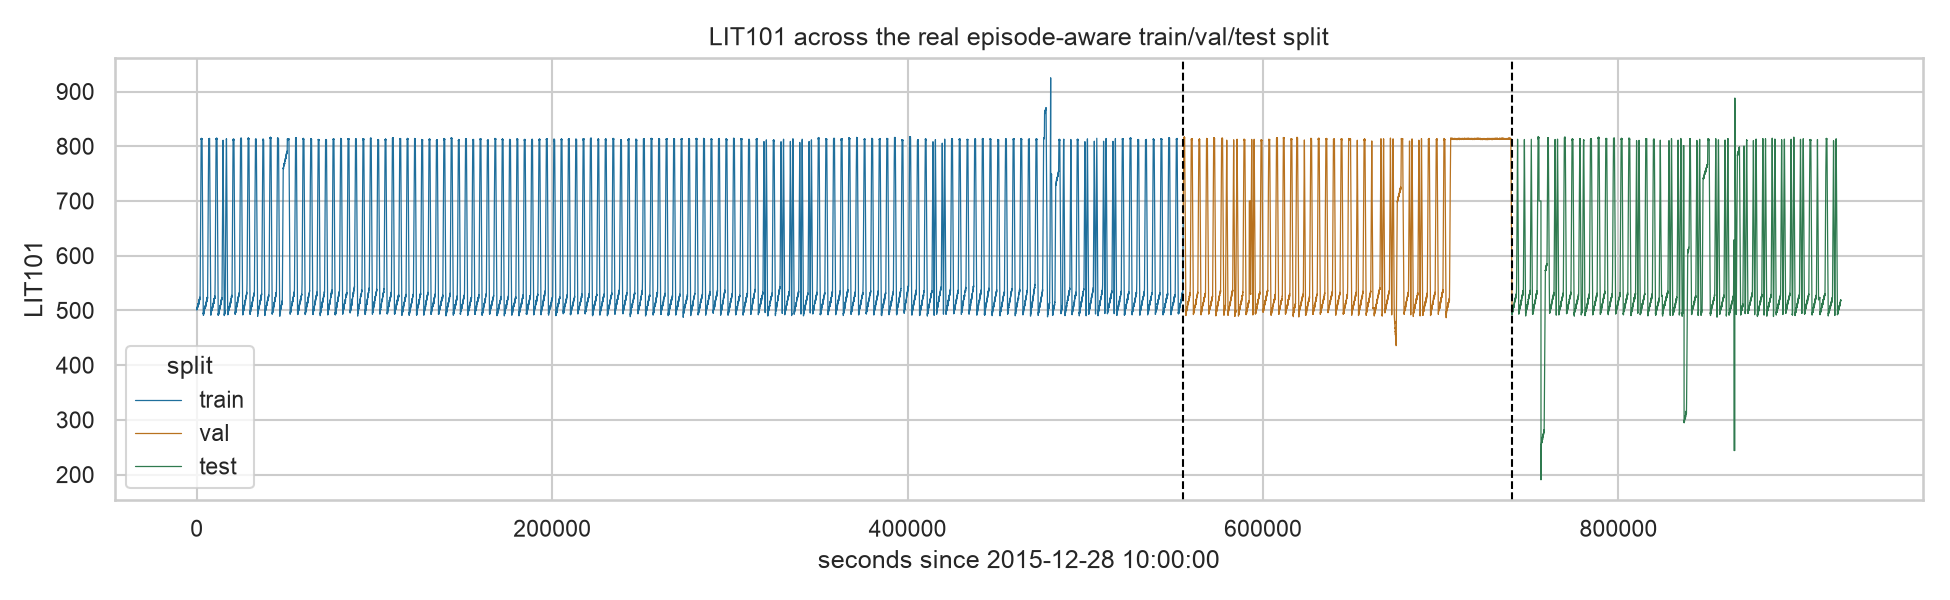

In [9]:
from visualize import plot_split_timeline

split_png = fig_dir / f"{DATASET}-split-timeline.png"
plot_split_timeline(df_raw, split, "LIT101", split_png)
display(Image(filename=str(split_png)))


## The detectors

Every detector shares one interface — `detector.fit(split)` then
`detector.score(X)` — defined in `src/models.py`. That uniformity is what
lets the same evaluation code run over every model, on every dataset, without
special cases.

| name | family | supervised? | what the score measures |
|---|---|---|---|
| `random` | baseline | – | pure noise; the sanity floor every real model must beat |
| `xgboost` | gradient boosting | yes | each row scored independently, no explicit memory of the past |
| `xgboost_lags` | gradient boosting | yes | same, plus engineered lag/rolling/diff features so it can approximate short-term memory |
| `lstm_ae` | deep (autoencoder) | no (trained on normal rows only) | reconstruction error over a 60-second window — measures *compressibility* |
| `lstm_forecast` | deep (forecaster) | no (trained on normal rows only) | one-step prediction error — measures *predictability*, sees temporal structure the autoencoder cannot |
| `naive_bayes` | classical/shallow baseline | yes | per-feature Gaussian likelihood ratio |
| `random_forest` | classical/shallow baseline | yes | majority vote over bagged decision trees |
| `oner` | classical/shallow baseline | yes | one hand-picked feature, binned; the simplest rule that could work |
| `j48` | classical/shallow baseline | yes | single decision tree (C4.5 stand-in) |
| `nnge_stub_knn` | classical/shallow baseline | yes | k-NN vote (stand-in for NNge's merged exemplars) |
| `svm` | classical/shallow baseline | yes | RBF-kernel SVM via SMO, trained on a stratified subsample |
| `cnn_classifier` | deep (1D CNN) | yes | Conv1d stack + global average pooling, trained directly on labelled attack windows |

The deep family is deliberately represented by **two** models (`lstm_ae`,
`lstm_forecast`). Reporting only the autoencoder would misattribute a
scoring-rule limitation to deep learning as a whole — see
`LSTMAutoencoderDetector`'s docstring in `models.py` for the full argument.
`cnn_classifier` is a third, different deep family again: supervised AND
windowed, where the two LSTMs are windowed but unsupervised and `xgboost` is
supervised but row-independent — see `CNNClassifierDetector`'s docstring.

The six classical/shallow models round out the traditional-ML side of the
benchmark alongside `xgboost` — cheap, well-understood techniques (a
probabilistic classifier, bagged trees, a single tree, a rule baseline, an
instance-based method, and a kernel method) evaluated on this notebook's
chronological split, same threshold rule as everything else. See the
"classical / shallow supervised baselines" section of `models.py` for exactly
which are faithful implementations and which are deliberate stand-ins (`j48`
for C4.5, `nnge_stub_knn` for NNge's merged-exemplar matching).


In [10]:
from models import REGISTRY

MODEL_NAMES = [
    "random", "xgboost", "xgboost_lags", "lstm_ae", "lstm_forecast",
    "naive_bayes", "random_forest", "oner", "j48", "nnge_stub_knn", "svm",
    "cnn_classifier",
]
print("registered models:", list(REGISTRY))

registered models: ['random', 'xgboost', 'xgboost_lags', 'lstm_ae', 'lstm_forecast', 'naive_bayes', 'random_forest', 'oner', 'j48', 'nnge_stub_knn', 'svm', 'cnn_classifier']


## Evaluation protocol: pointwise vs point-adjust

This is the project's central methodological point (`src/evaluate.py`), and
it applies identically regardless of which dataset is loaded above.

- **Pointwise** — each second judged independently. Strict, and the honest
  number to read first.
- **Point-adjust** — if a model flags *any one second* inside a ground-truth
  attack window, the *entire window* counts as detected. This is the
  dominant protocol in published ICS anomaly detection work, and Kim et al.
  (AAAI 2022) showed it lets a random score beat published state of the art.

`random_baseline_check()` reproduces that result directly: pure noise scored
against synthetic anomaly segments. If point-adjusted F1 comes back high
while pointwise F1 stays near zero, the metric implementation is correct —
and the literature's typical benchmark numbers are exposed as an artefact
of the protocol, not evidence the model actually works. This check does not
depend on `DATASET` — it runs on synthetic data every time as a fixed sanity
check.


In [11]:
from evaluate import random_baseline_check

sanity = random_baseline_check()
print(sanity.summary())


random noise on synthetic
  anomaly rate     0.0953   threshold 0.9903
  ROC-AUC          0.4979    PR-AUC 0.0948
  pointwise      P 0.108  R 0.011  F1 0.021  MCC 0.004
  point-adjusted P 0.910  R 0.945  F1 0.927  MCC 0.919
  F1 inflation     +0.906


## Run the benchmark

`experiment.run()` fits each detector on the training window, picks a
threshold at the 97th percentile of *validation* scores (never test), scores
the test window, evaluates under both protocols, prints a summary per model,
and saves the full results as JSON under `results/` — named from `DATASET`,
so runs against different datasets never overwrite each other.

The two LSTM models are the slow part (8 and 20 training epochs respectively)
— this cell's runtime scales with how much training data `DATASET` has.


In [12]:
from experiment import run

results = run(split, MODEL_NAMES, tag="notebook")


swat: 51 features
  train  555,071 rows  anomaly rate 0.0093
  val    185,024 rows  anomaly rate 0.2295
  test   185,024 rows  anomaly rate 0.0376

  random ...


random on swat
  anomaly rate     0.0376   threshold 0.9698
  ROC-AUC          0.4974    PR-AUC 0.0376
  pointwise      P 0.037  R 0.030  F1 0.033  MCC -0.001
  point-adjusted P 0.564  R 1.000  F1 0.721  MCC 0.740
  F1 inflation     +0.688

  xgboost ...


xgboost on swat
  anomaly rate     0.0376   threshold 0.4158
  ROC-AUC          0.6010    PR-AUC 0.0717
  pointwise      P 0.055  R 0.188  F1 0.085  MCC 0.035
  point-adjusted P 0.097  R 0.345  F1 0.151  MCC 0.122
  F1 inflation     +0.066

  xgboost+lags[1, 5, 30] ...


xgboost+lags[1, 5, 30] on swat
  anomaly rate     0.0376   threshold 0.4999
  ROC-AUC          0.5618    PR-AUC 0.0594
  pointwise      P 0.026  R 0.042  F1 0.032  MCC -0.016
  point-adjusted P 0.140  R 0.260  F1 0.182  MCC 0.148
  F1 inflation     +0.150

  lstm_ae(w=60,h=128-64) ...


    epoch   0  loss 0.18427


...

    epoch  11  loss 0.00730


    epoch  12  loss 0.01087


    epoch  13  loss 0.00837


    epoch  14  loss 0.00749


cnn_classifier(w=60,f=64) on swat
  anomaly rate     0.0376   threshold 0.6889
  ROC-AUC          0.4359    PR-AUC 0.2110
  pointwise      P 0.466  R 0.194  F1 0.274  MCC 0.284
  point-adjusted P 0.555  R 0.278  F1 0.371  MCC 0.377
  F1 inflation     +0.096

saved -> results/swat-notebook-20261011-121956.json

model                        PR-AUC    F1 pw   F1 adj  inflation
----------------------------------------------------------------
random                        0.038    0.033    0.721     +0.688
xgboost                       0.072    0.085    0.151     +0.066
xgboost+lags[1, 5, 30]        0.059    0.032    0.182     +0.150
lstm_ae(w=60,h=128-64)        0.431    0.073    0.073     +0.000
lstm_forecast(w=60,h=64)      0.490    0.073    0.074     +0.001
naive_bayes                   0.323    0.476    0.509     +0.033
random_forest                 0.085    0.027    0.189     +0.161
oner                          0.037    0.057    0.442     +0.385
j48                           0.038   

## Results, tidied

Same numbers as the printed table above, reshaped into a DataFrame for
easier reading/plotting. `f1_inflation` is `f1_point_adjust - f1_pointwise`
— the headline number. Large inflation means a model is close to guessing
and getting lucky once per attack window; read the pointwise column first.


In [13]:
summary = pd.DataFrame([
    {
        "model": r.meta.get("model"),
        "roc_auc": r.roc_auc,
        "pr_auc": r.pr_auc,
        "f1_pointwise": r.pointwise.f1,
        "f1_point_adjust": r.point_adjusted.f1,
        "f1_inflation": r.f1_inflation,
    }
    for r in results
]).set_index("model")

summary


,roc_auc,pr_auc,f1_pointwise,f1_point_adjust,f1_inflation
model,,,,,
random,0.497445,0.037568,0.032972,0.721172,0.688200
xgboost,0.600965,0.071699,0.085266,0.151258,0.065992
"xgboost+lags[1, 5, 30]",0.561850,0.059376,0.031947,0.182093,0.150146
"lstm_ae(w=60,h=128-64)",0.779511,0.431290,0.073235,0.073235,0.000000
"lstm_forecast(w=60,h=64)",0.800809,0.489591,0.073257,0.073953,0.000696
naive_bayes,0.651167,0.322673,0.476323,0.509080,0.032757
random_forest,0.703675,0.084939,0.027464,0.188617,0.161153
oner,0.487136,0.037373,0.056987,0.441954,0.384966
j48,0.502681,0.037844,0.055933,0.284388,0.228455


## Loss curves and score plots: which model is actually doing best

`experiment.run()` above already produced the authoritative metrics for every registered model — that's the project's one source of truth for numbers (see `src/experiment.py`'s docstring). It doesn't keep the raw per-row scores, though, and a plot needs those. So this section re-fits a **representative subset** — one classical model with `feature_importances_` (`random_forest`), one gradient-boosted tree (`xgboost`), and both deep families (`lstm_ae`, `cnn_classifier`) — using `fit_and_score()`, the exact same function `run_one()` calls internally, imported rather than copied.

Refitting a few models twice (once above for metrics, once here for scores) is the deliberate tradeoff over re-plumbing every detector's raw scores through `experiment.py`'s saved JSON.


In [14]:
from experiment import fit_and_score

DIAG_MODELS = ["random_forest", "xgboost", "lstm_ae", "cnn_classifier"]

diag_detectors, diag_thresholds, diag_scores = {}, {}, {}
for name in DIAG_MODELS:
    print(f"--- {name} ---")
    detector = REGISTRY[name]()
    threshold, test_scores = fit_and_score(split, detector)
    diag_detectors[name] = detector
    diag_thresholds[name] = threshold
    diag_scores[name] = test_scores


--- random_forest ---


--- xgboost ---


--- lstm_ae ---


    epoch   0  loss 0.18427


    epoch   1  loss 0.10131


...

    epoch  10  loss 0.00807


    epoch  11  loss 0.00730


    epoch  12  loss 0.01087


    epoch  13  loss 0.00837


    epoch  14  loss 0.00749


saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-random_forest-importance.png


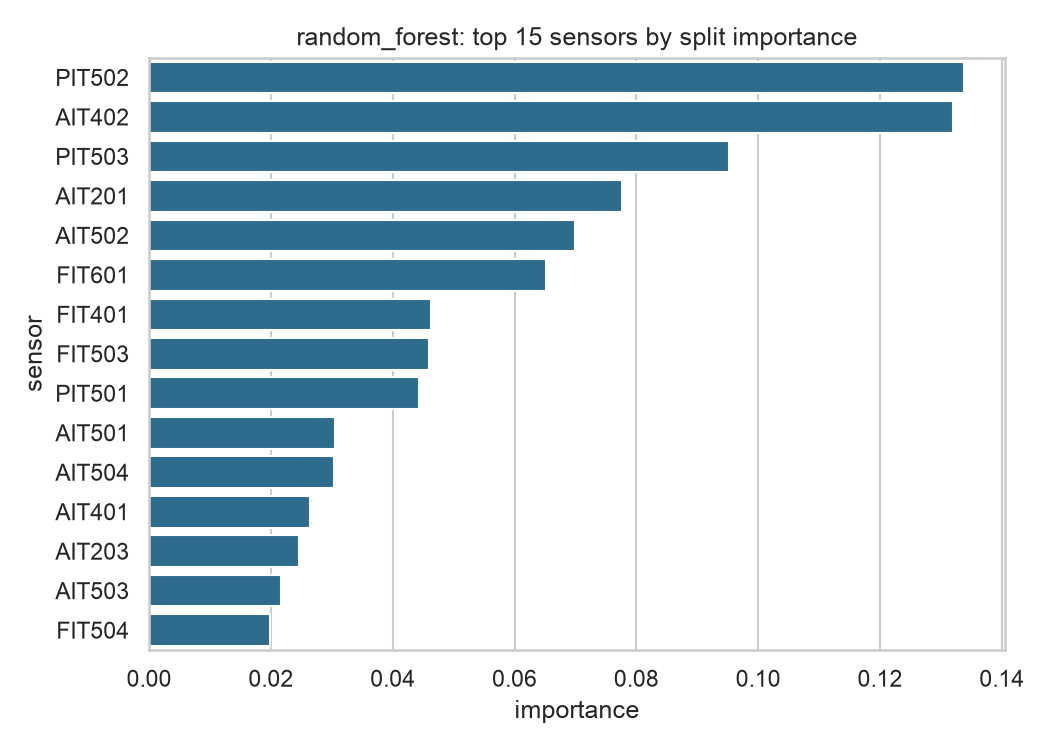

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-random_forest-scores.png


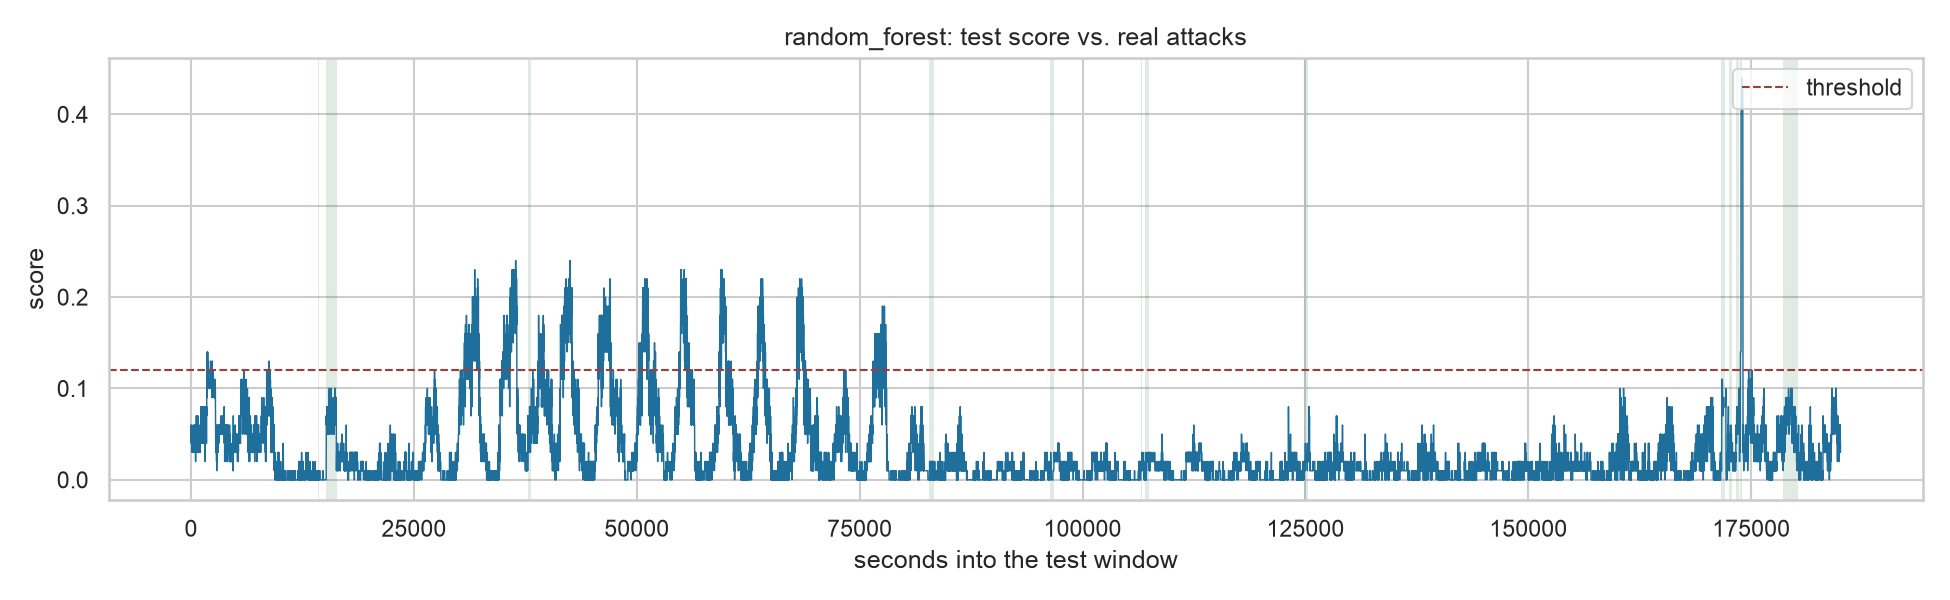

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-random_forest-dist.png


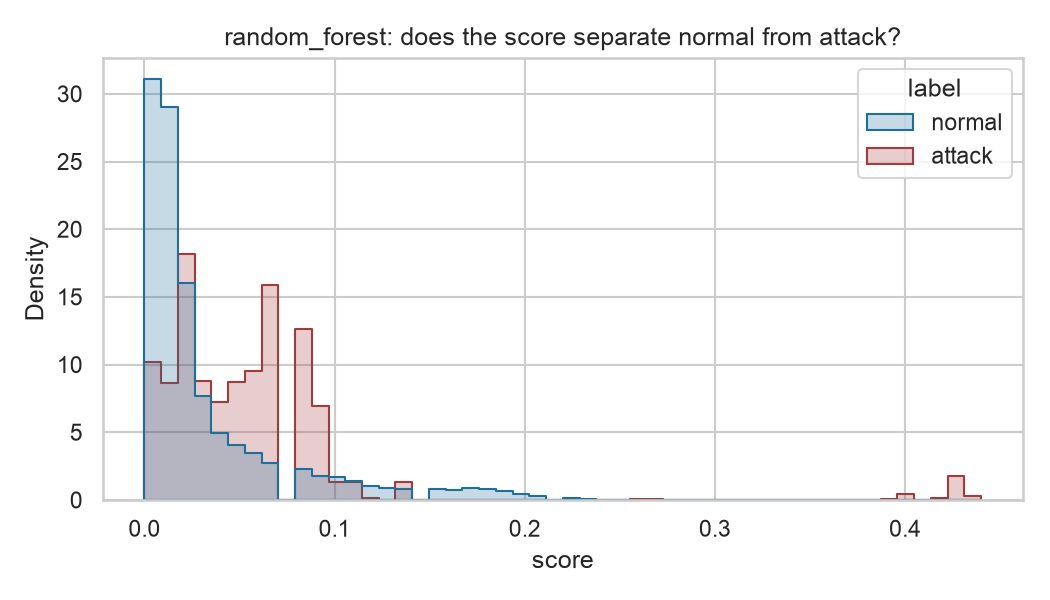

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-xgboost-importance.png


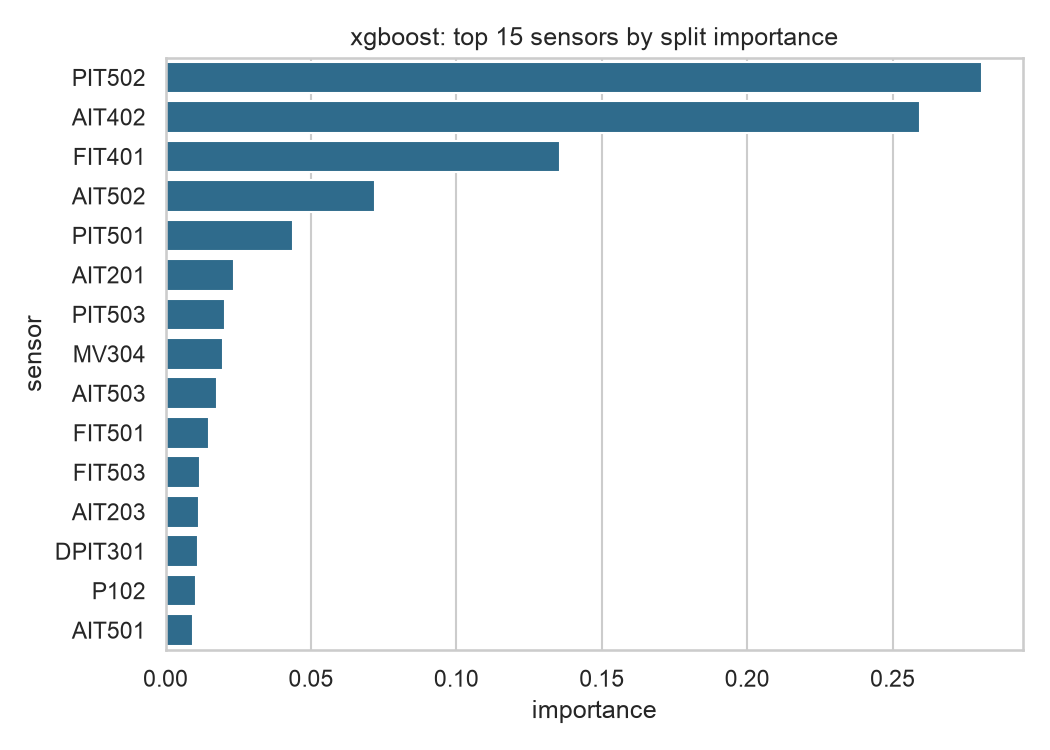

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-xgboost-scores.png


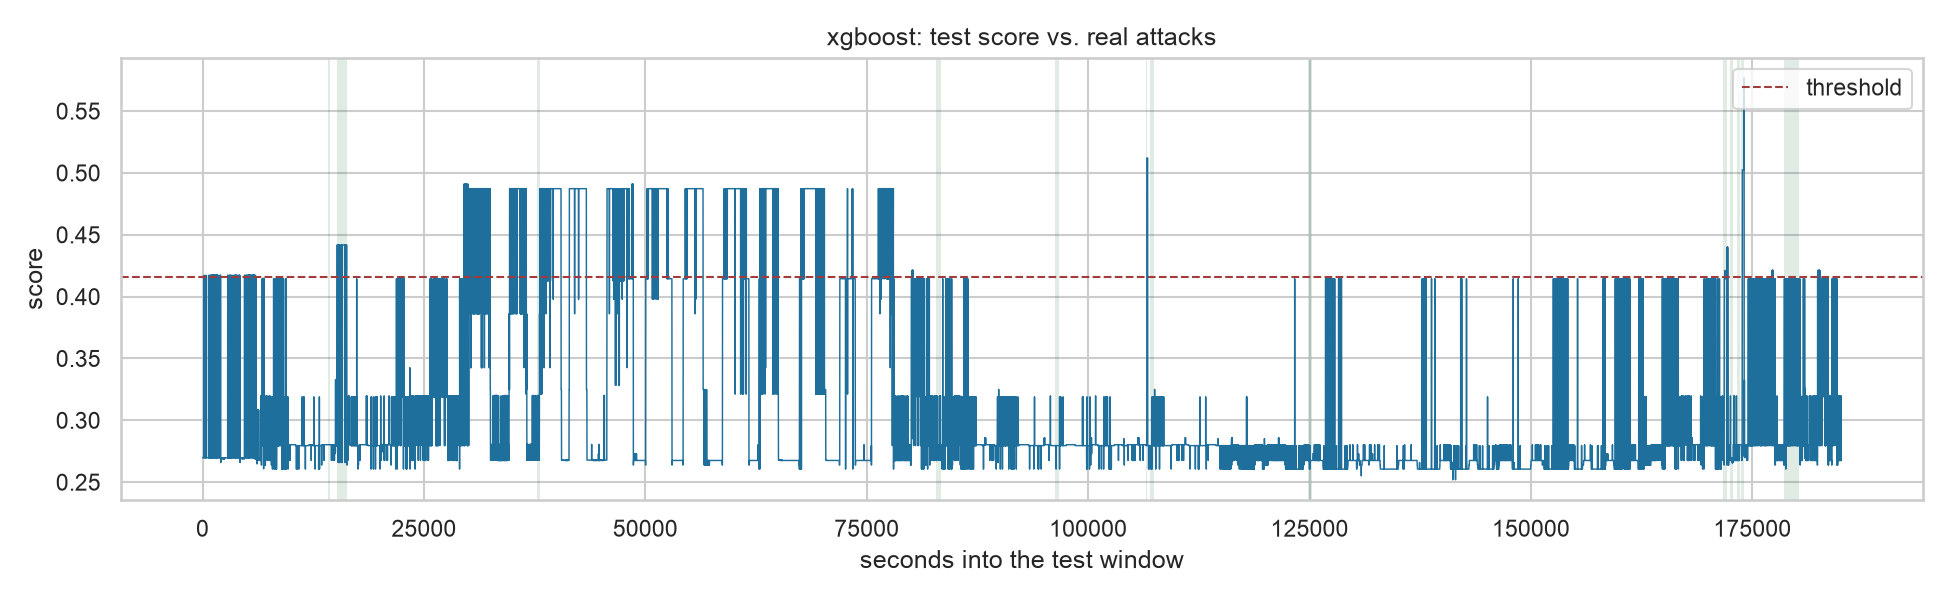

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-xgboost-dist.png


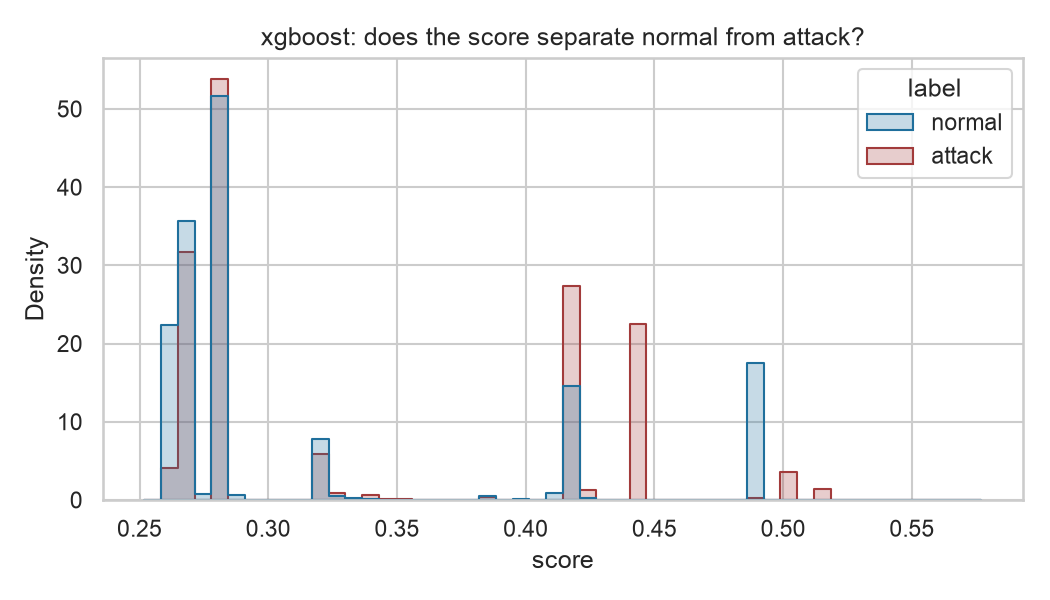

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-lstm_ae-loss.png


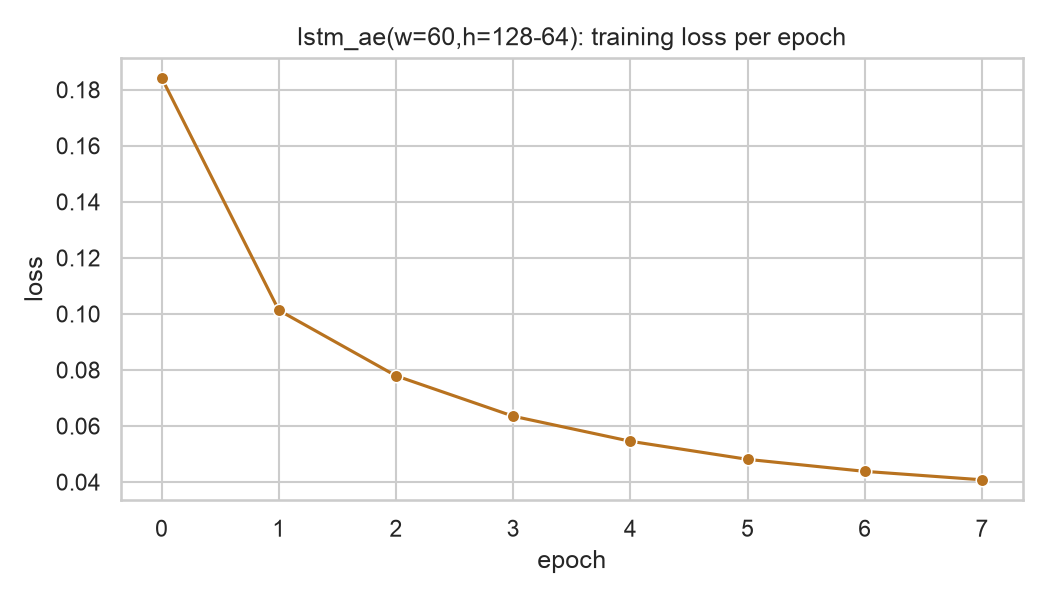

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-lstm_ae-scores.png


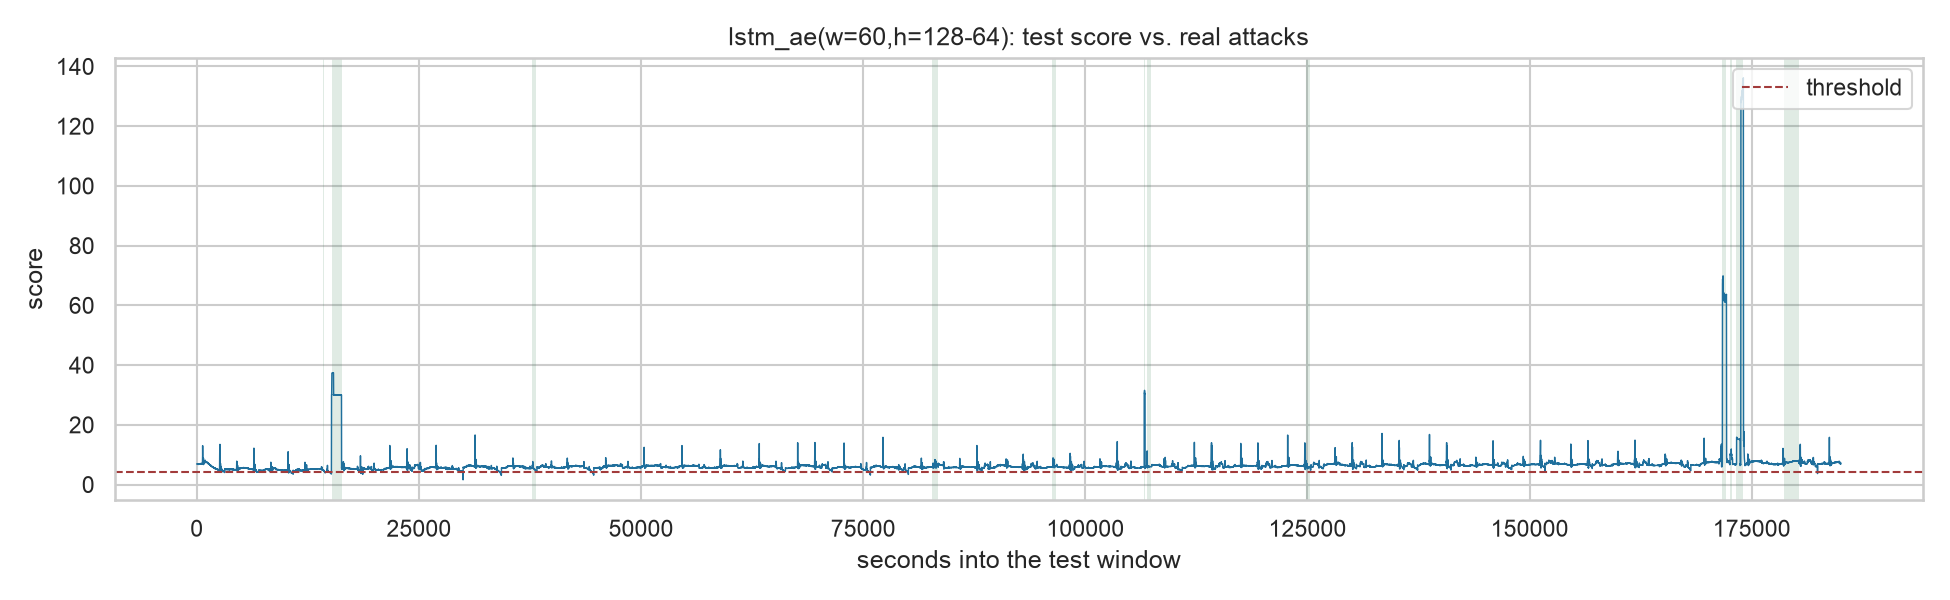

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-lstm_ae-dist.png


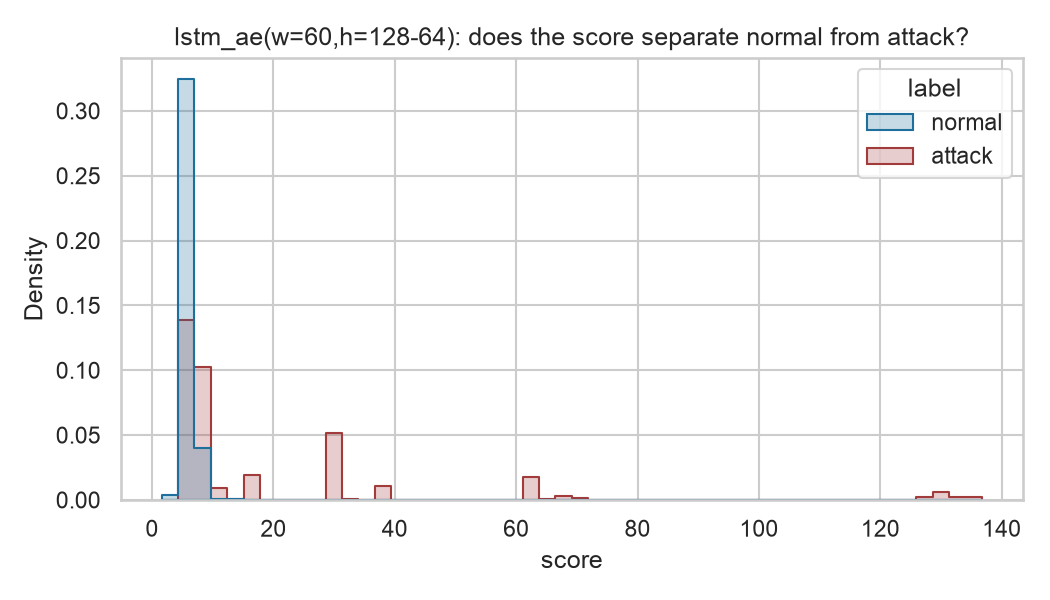

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-cnn_classifier-loss.png


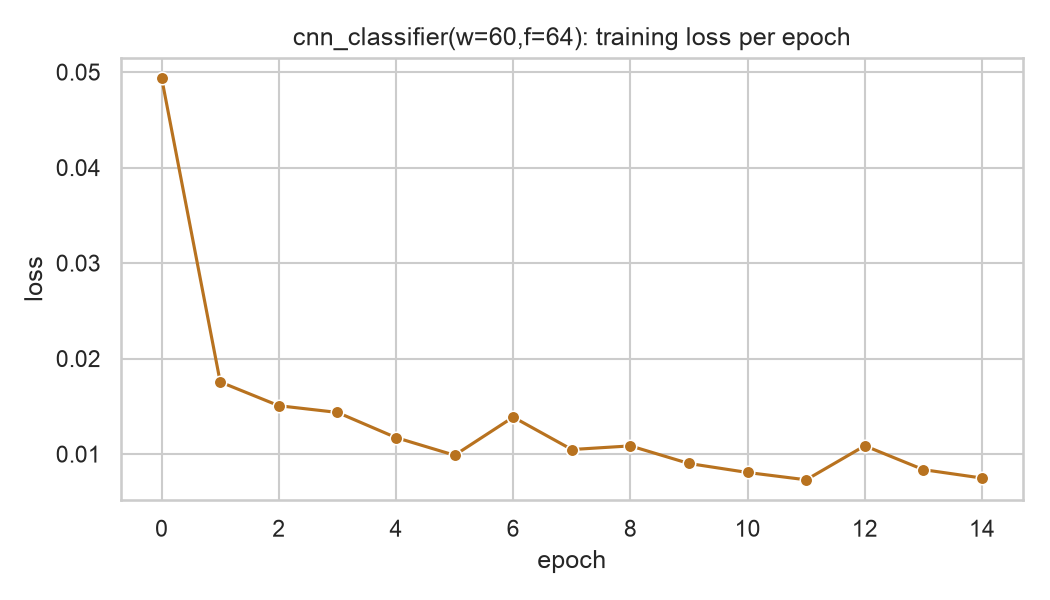

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-cnn_classifier-scores.png


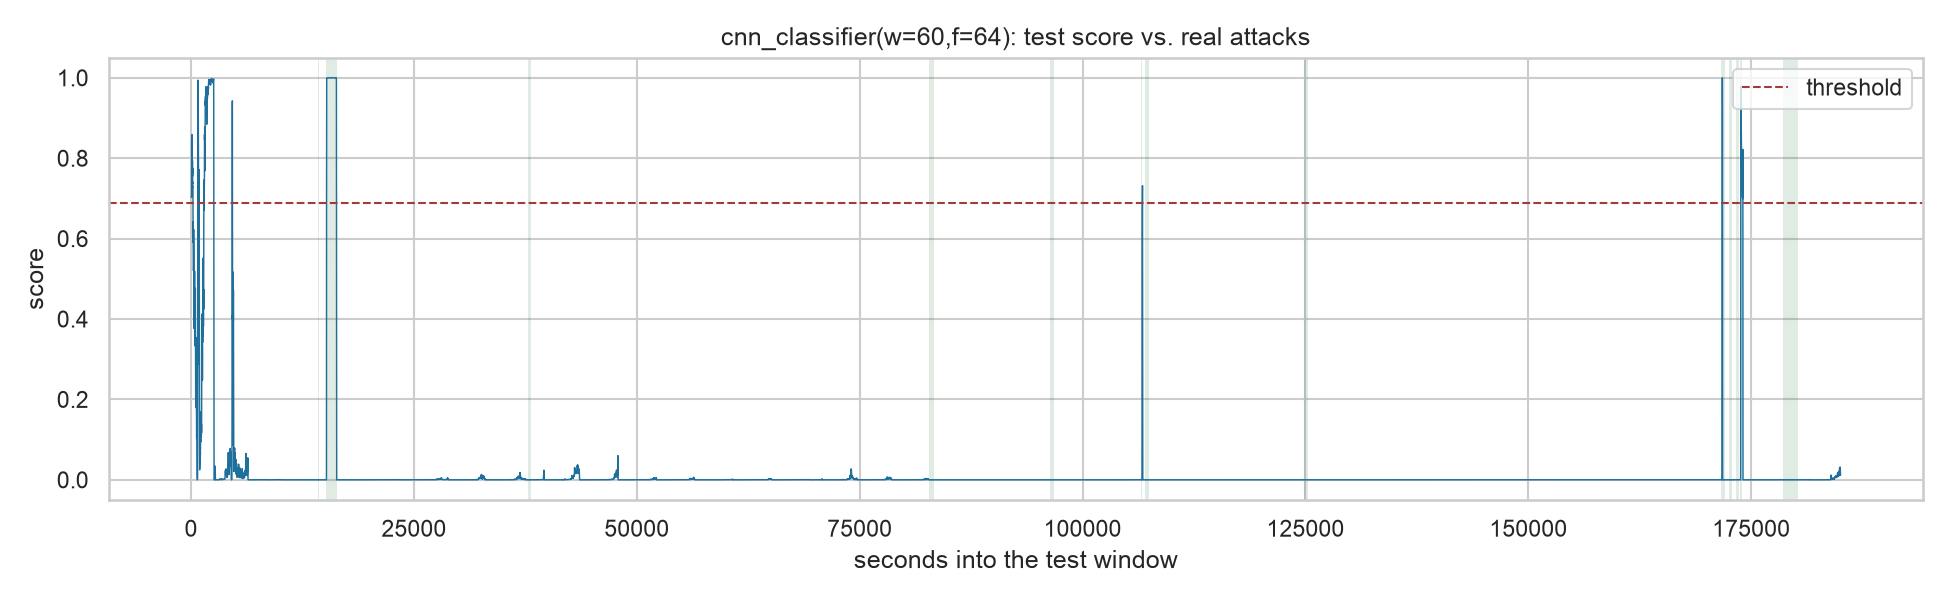

saved -> /Users/santhosh/Desktop/urex-ics/results/figures/swat-cnn_classifier-dist.png


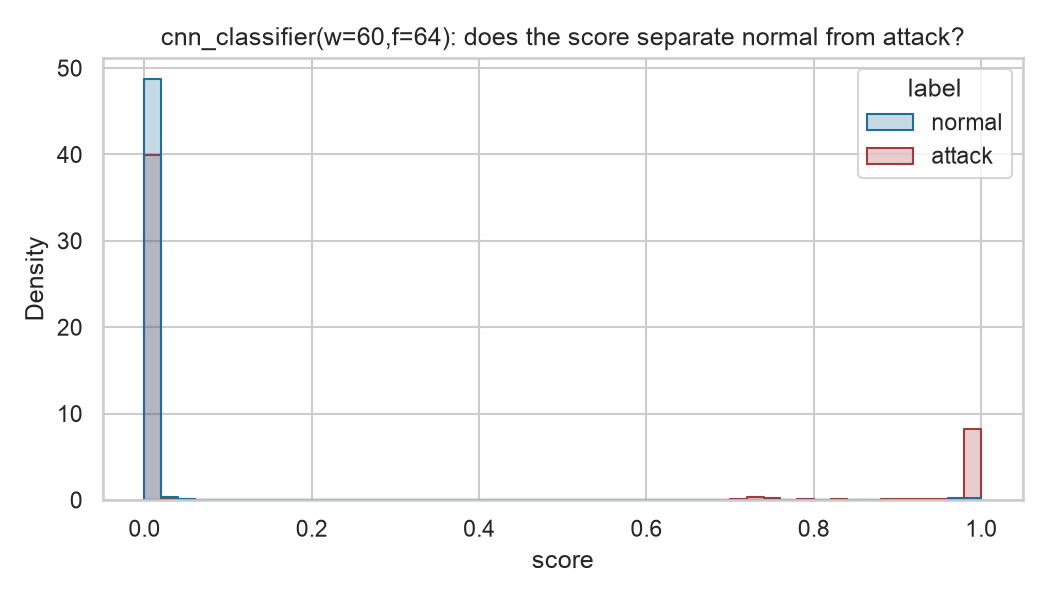

In [15]:
from visualize import (
    plot_feature_importance, plot_loss_curve,
    plot_score_timeline, plot_score_distribution,
)

for name in DIAG_MODELS:
    detector = diag_detectors[name]
    scores = diag_scores[name]
    threshold = diag_thresholds[name]

    if hasattr(getattr(detector, "model", None), "feature_importances_"):
        p = fig_dir / f"{DATASET}-{name}-importance.png"
        plot_feature_importance(detector, split.feature_names, p)
        display(Image(filename=str(p)))

    if getattr(detector, "loss_history", None):
        p = fig_dir / f"{DATASET}-{name}-loss.png"
        plot_loss_curve(detector, p)
        display(Image(filename=str(p)))

    p = fig_dir / f"{DATASET}-{name}-scores.png"
    plot_score_timeline(
        split.y_test, scores, threshold, p,
        f"{detector.name}: test score vs. real attacks",
    )
    display(Image(filename=str(p)))

    p = fig_dir / f"{DATASET}-{name}-dist.png"
    plot_score_distribution(
        split.y_test, scores, p,
        f"{detector.name}: does the score separate normal from attack?",
    )
    display(Image(filename=str(p)))


### Side by side

Same four models, pulled back out of the full results table above by name, sorted by PR-AUC (the threshold-free ranking) so the best model on this split is just whichever row is on top.


In [16]:
from compare_models import _matches

mask = summary.index.to_series().apply(
    lambda n: any(_matches(n, m) for m in DIAG_MODELS)
)
summary[mask].sort_values("pr_auc", ascending=False)


,roc_auc,pr_auc,f1_pointwise,f1_point_adjust,f1_inflation
model,,,,,
"lstm_ae(w=60,h=128-64)",0.779511,0.431290,0.073235,0.073235,0.000000
"cnn_classifier(w=60,f=64)",0.435883,0.211048,0.274395,0.370647,0.096252
random_forest,0.703675,0.084939,0.027464,0.188617,0.161153
xgboost,0.600965,0.071699,0.085266,0.151258,0.065992
"xgboost+lags[1, 5, 30]",0.561850,0.059376,0.031947,0.182093,0.150146


## How to read this

- **`random`'s `f1_inflation`** should be large and positive — that's the
  Kim et al. effect confirmed on real attack data, not just the synthetic
  sanity check above. If any real model's inflation is comparably large,
  its point-adjusted score is not trustworthy evidence it works.
- **Deep vs boosting**: check `DATASET_INFO[DATASET]["temporal_dependency"]`
  (printed when the dataset loaded above) against what `f1_pointwise` shows.
  The project's hypothesis is that sequence models (`lstm_ae`,
  `lstm_forecast`) have a structural advantage on high-temporal-dependency
  datasets over row-independent gradient boosting (`xgboost`); low-dependency
  datasets (Morris, once its loader exists) are the contrast case where
  boosting is expected to hold its own or win.
- **`xgboost` vs `xgboost_lags`**: whether engineered lag features close the
  gap with the deep models, widen it, or make boosting worse — all three
  are informative outcomes for the project's central question (how much of
  deep learning's advantage is architectural vs recoverable with feature
  engineering). Worth comparing across datasets, not just within one.
- Full precision/recall/MCC per model, per protocol, is in the saved JSON
  under `results/<DATASET>-notebook-<timestamp>.json` (path printed above).

- **The loss-curve / score-plot section** above is the fastest way to sanity-check a model visually: a loss curve that never goes down means training is broken before any metric is even worth reading; a score distribution with no separation between the "normal" and "attack" histograms means the metric number, whatever it says, isn't measuring a working detector.
